# Jamboree Admission — Exploratory Data Analysis

Explore the admissions data and identify preprocessing and modeling implications. The target is the continuous **Chance of Admit** value. The serial number is an identifier, not a predictive feature.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
DATA_PATH = Path("Jamboree_Admission.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path.cwd() / "Jamboree_Admission.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
print(f"Loaded {DATA_PATH.resolve()}")
df.head()

Loaded /Users/sharath/project/Jamboree_Admission.csv


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


## Structure and data quality

Check the table dimensions, normalized column labels, inferred types, missingness, duplicate records, and basic statistics.

In [7]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().rename("missing").to_frame())
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.describe().T)

Shape: (500, 9)
Columns: ['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


,dtype
Serial No.,int64
GRE Score,int64
TOEFL Score,int64
University Rating,int64
SOP,float64
LOR,float64
CGPA,float64
Research,int64
Chance of Admit,float64


,missing
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Serial No.,500.0,250.50000,144.481833,1.00,125.7500,250.50,375.25,500.00
GRE Score,500.0,316.47200,11.295148,290.00,308.0000,317.00,325.00,340.00
TOEFL Score,500.0,107.19200,6.081868,92.00,103.0000,107.00,112.00,120.00
University Rating,500.0,3.11400,1.143512,1.00,2.0000,3.00,4.00,5.00
SOP,500.0,3.37400,0.991004,1.00,2.5000,3.50,4.00,5.00
LOR,500.0,3.48400,0.925450,1.00,3.0000,3.50,4.00,5.00
CGPA,500.0,8.57644,0.604813,6.80,8.1275,8.56,9.04,9.92
Research,500.0,0.56000,0.496884,0.00,0.0000,1.00,1.00,1.00
Chance of Admit,500.0,0.72174,0.141140,0.34,0.6300,0.72,0.82,0.97


## Target distribution

Inspect the range and shape of the admission-chance outcome before selecting a regression metric.

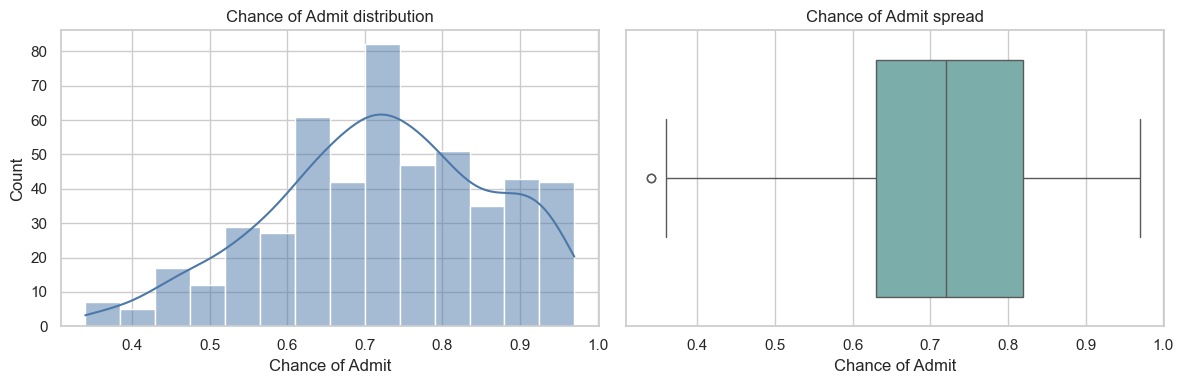

count    500.00000
mean       0.72174
std        0.14114
min        0.34000
25%        0.63000
50%        0.72000
75%        0.82000
max        0.97000
Name: Chance of Admit, dtype: float64

In [3]:
TARGET = "Chance of Admit"
IDENTIFIER = "Serial No."
if TARGET not in df.columns:
    raise KeyError(f"Expected target column {TARGET!r}; found {df.columns.tolist()}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0], color="#4C78A8")
axes[0].set_title("Chance of Admit distribution")
sns.boxplot(x=df[TARGET], ax=axes[1], color="#72B7B2")
axes[1].set_title("Chance of Admit spread")
plt.tight_layout()
plt.show()
df[TARGET].describe()

## Feature distributions and relationships

Exclude the row identifier from feature analysis. These plots help spot scale differences, discrete variables, and nonlinear relationships.

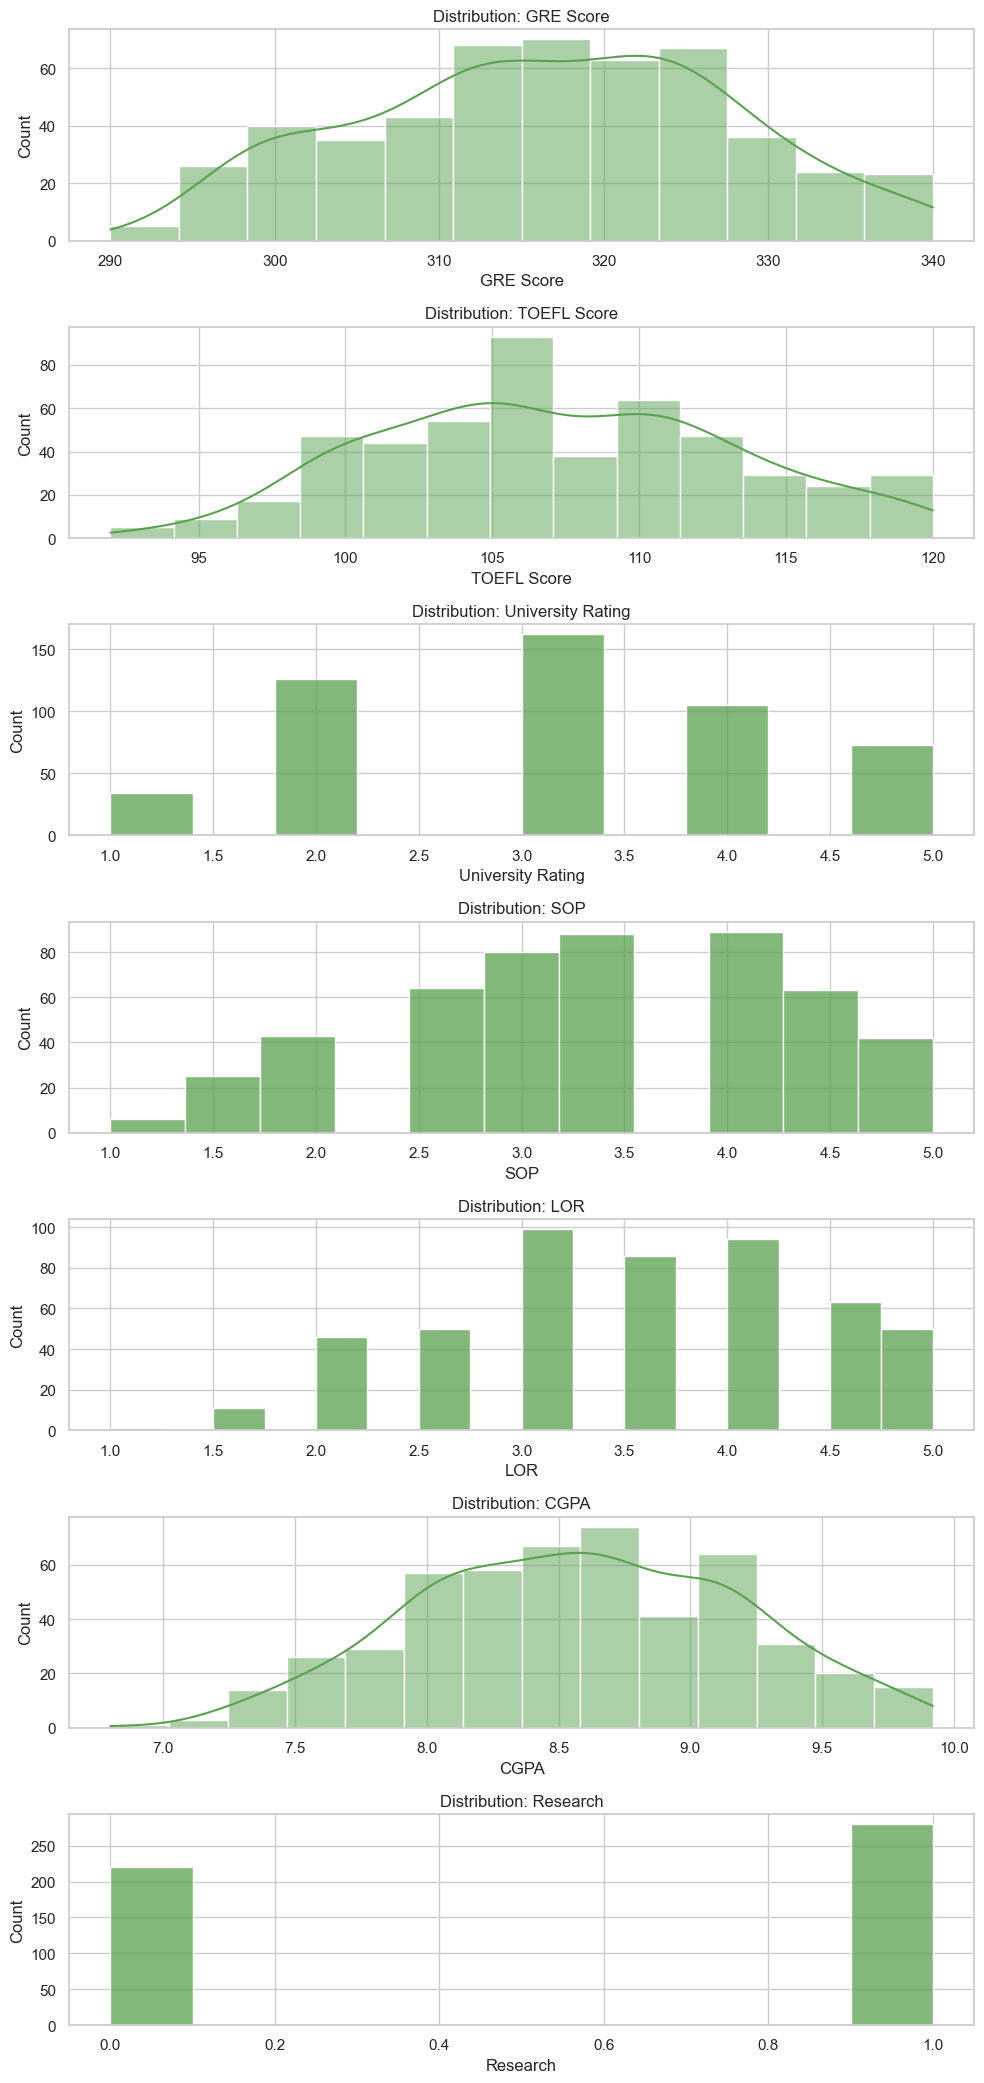

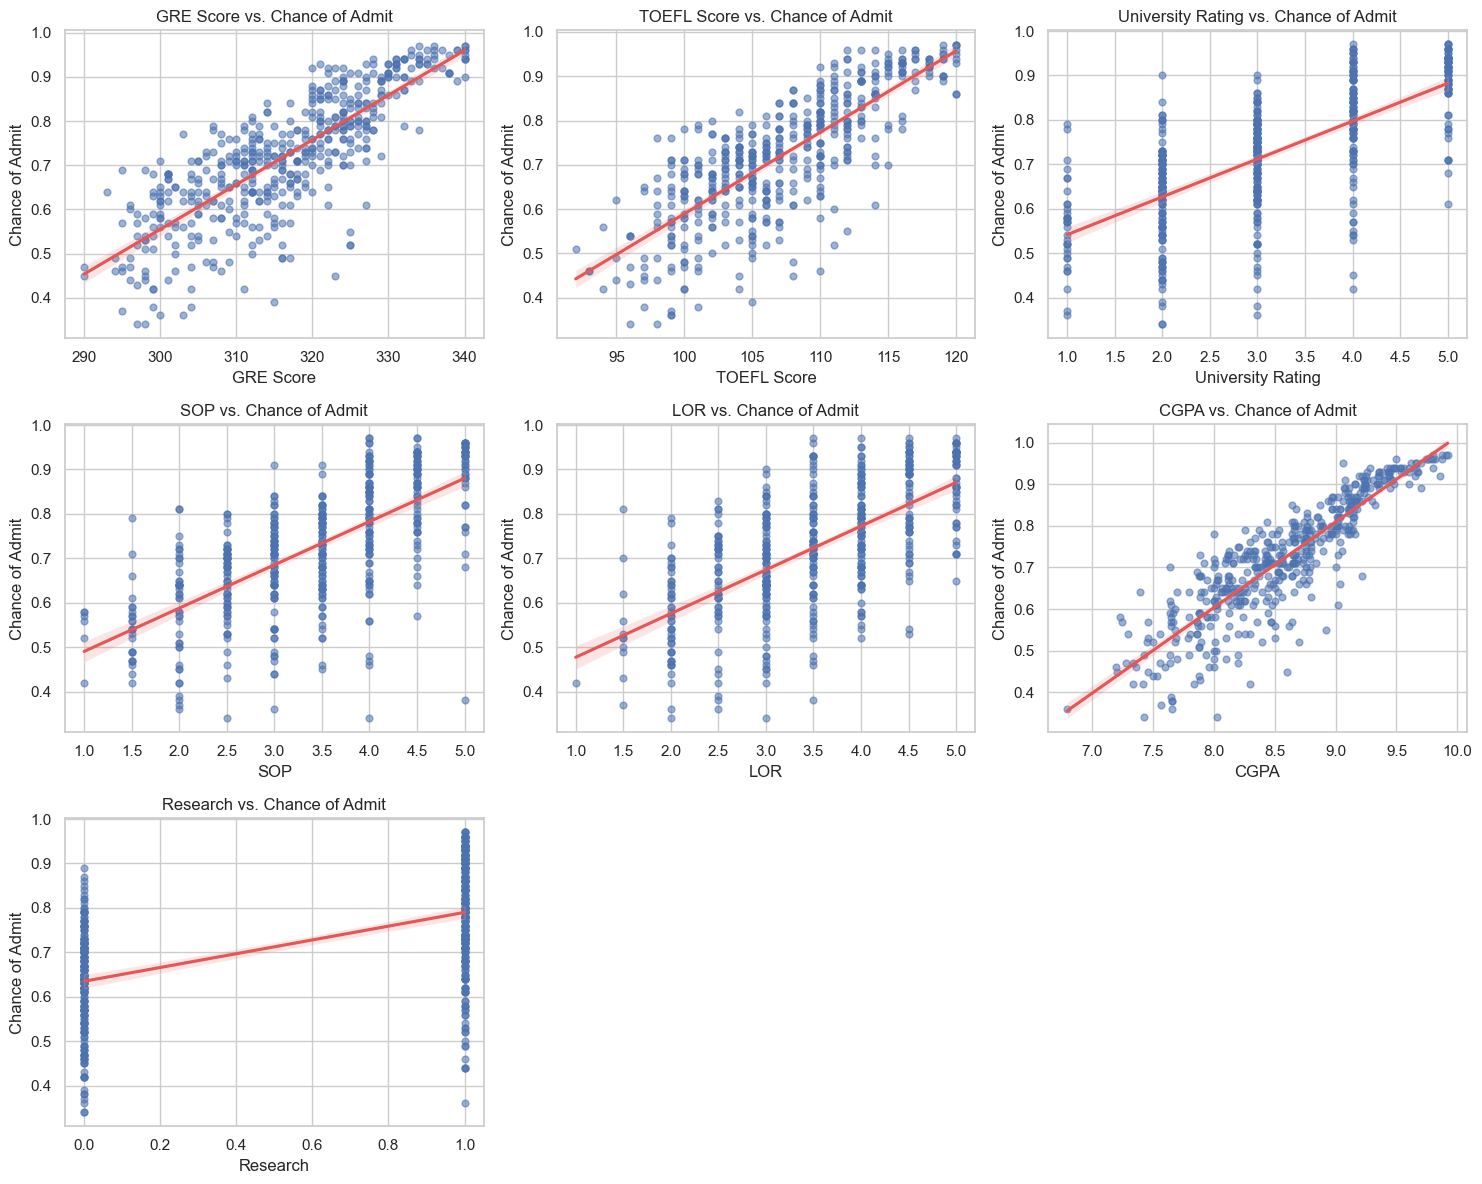

In [4]:
features = df.drop(columns=[TARGET, IDENTIFIER], errors="ignore")
fig, axes = plt.subplots(len(features.columns), 1, figsize=(10, 3 * len(features.columns)))
for column, ax in zip(features.columns, np.atleast_1d(axes)):
    sns.histplot(data=df, x=column, kde=(df[column].nunique() > 10), ax=ax, color="#59A14F")
    ax.set_title(f"Distribution: {column}")
plt.tight_layout()
plt.show()

plot_columns = list(features.columns)
ncols = 3
nrows = int(np.ceil(len(plot_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
for column, ax in zip(plot_columns, np.ravel(axes)):
    sns.regplot(data=df, x=column, y=TARGET, ax=ax, scatter_kws={"alpha": 0.55, "s": 24}, line_kws={"color": "#E45756"})
    ax.set_title(f"{column} vs. {TARGET}")
for ax in np.ravel(axes)[len(plot_columns):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## Correlations and modeling notes

Correlation is a useful first look at linear association, not proof of causation. The final cell produces data-dependent notes to guide the separate model-comparison script.

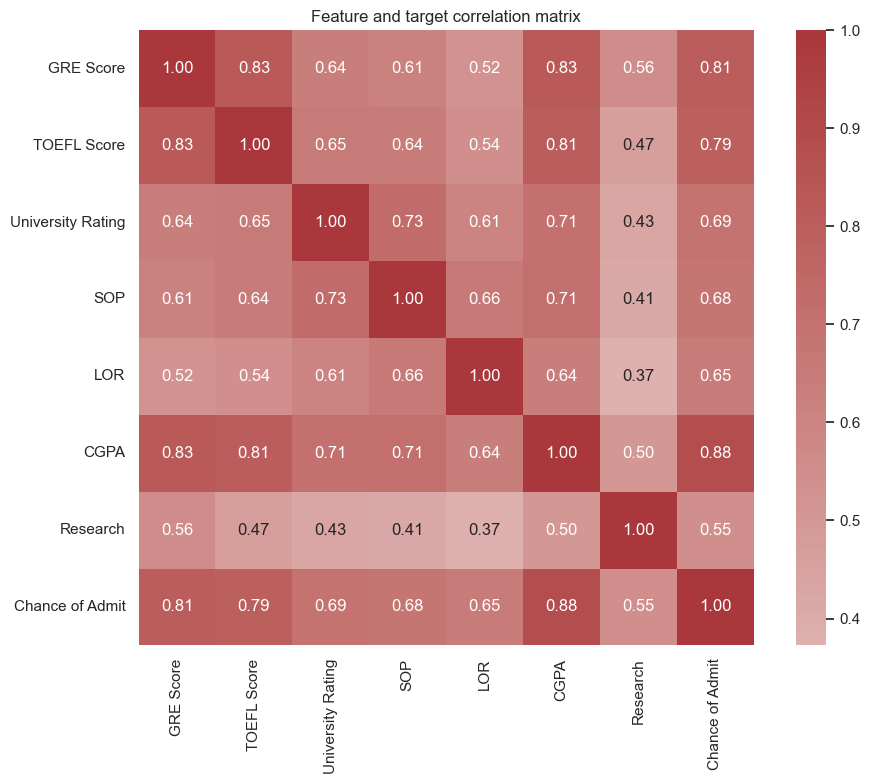

Absolute feature-target correlation ranking:


,correlation
CGPA,0.882413
GRE Score,0.810351
TOEFL Score,0.792228
University Rating,0.690132
SOP,0.684137
LOR,0.645365
Research,0.545871


Rows: 500; numeric target: True; missing cells: 0
Modeling notes:
- Exclude Serial No. because it identifies row order rather than applicant merit.
- Use a held-out test split and cross-validation on training data to compare regressors.
- Fit any imputation/scaling inside a training-only pipeline to avoid leakage.
- Compare MAE/RMSE alongside R-squared; do not interpret correlation as causation.


In [ ]:
analysis_df = df.drop(columns=[IDENTIFIER], errors="ignore")
corr = analysis_df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Feature and target correlation matrix")
plt.tight_layout()
plt.show()

feature_target_corr = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
print("Absolute feature-target correlation ranking:")
display(feature_target_corr.to_frame("correlation"))
print(f"Rows: {len(df)}; numeric target: {pd.api.types.is_numeric_dtype(df[TARGET])}; missing cells: {int(df.isna().sum().sum())}")


